# Spatial reasoning benchmark: reproducible analysis

**Completed:** 240 questions, executed PostGIS answer key, 120 fixture assertions, two Matplotlib figures.

**Not run:** LLM evaluations. These plots measure spatial relationships, not model accuracy.

The committed 40-airport OurAirports subset is public domain. Synthetic fixtures are original CC0 test scenes. See README.md and source_manifest.json for source, selection, license and checksums. Run from the repository root with Node 24 and Python 3.11; install `npm ci` and `pip install -r requirements.txt` first. Related questions share scene IDs; these are 60 base scenes, not 240 independent geographies.


In [1]:
from pathlib import Path
import csv, json, subprocess, sys
root = Path.cwd()
if not (root / "generate.py").exists():
    raise RuntimeError("Open this notebook from the repository root")
for command in [[sys.executable, "generate.py"], ["node", "ground_truth.mjs"]]:
    completed = subprocess.run(command, check=True, capture_output=True, text=True)
    print(completed.stdout, end="")


Generated 240 questions across 8 tasks.
PostGIS generated 240 answers; 120 independent fixture assertions passed.


In [2]:
with open("ground_truth_results.csv", newline="", encoding="utf-8") as f:
    results = list(csv.DictReader(f))
counts = {}
for row in results:
    counts[row["task"]] = counts.get(row["task"], 0) + 1
assert len(results) == 240 and len(counts) == 8 and set(counts.values()) == {30}
print(json.dumps(counts, indent=2))
print("LLM model calls: 0. No model accuracy claims.")


{
  "adjacency": 30,
  "containment": 30,
  "direction": 30,
  "distance": 30,
  "intersection": 30,
  "multi_step": 30,
  "radius": 30,
  "ranking": 30
}
LLM model calls: 0. No model accuracy claims.


In [3]:
completed = subprocess.run([sys.executable, "-m", "unittest", "test_evaluation.py"], check=True, capture_output=True, text=True)
print(completed.stdout + completed.stderr)
completed = subprocess.run([sys.executable, "analyze.py"], check=True, capture_output=True, text=True)
print(completed.stdout)


....
----------------------------------------------------------------------
Ran 4 tests in 0.000s

OK

Wrote two figures from real PostGIS outputs; all eight tasks contain 30 questions.



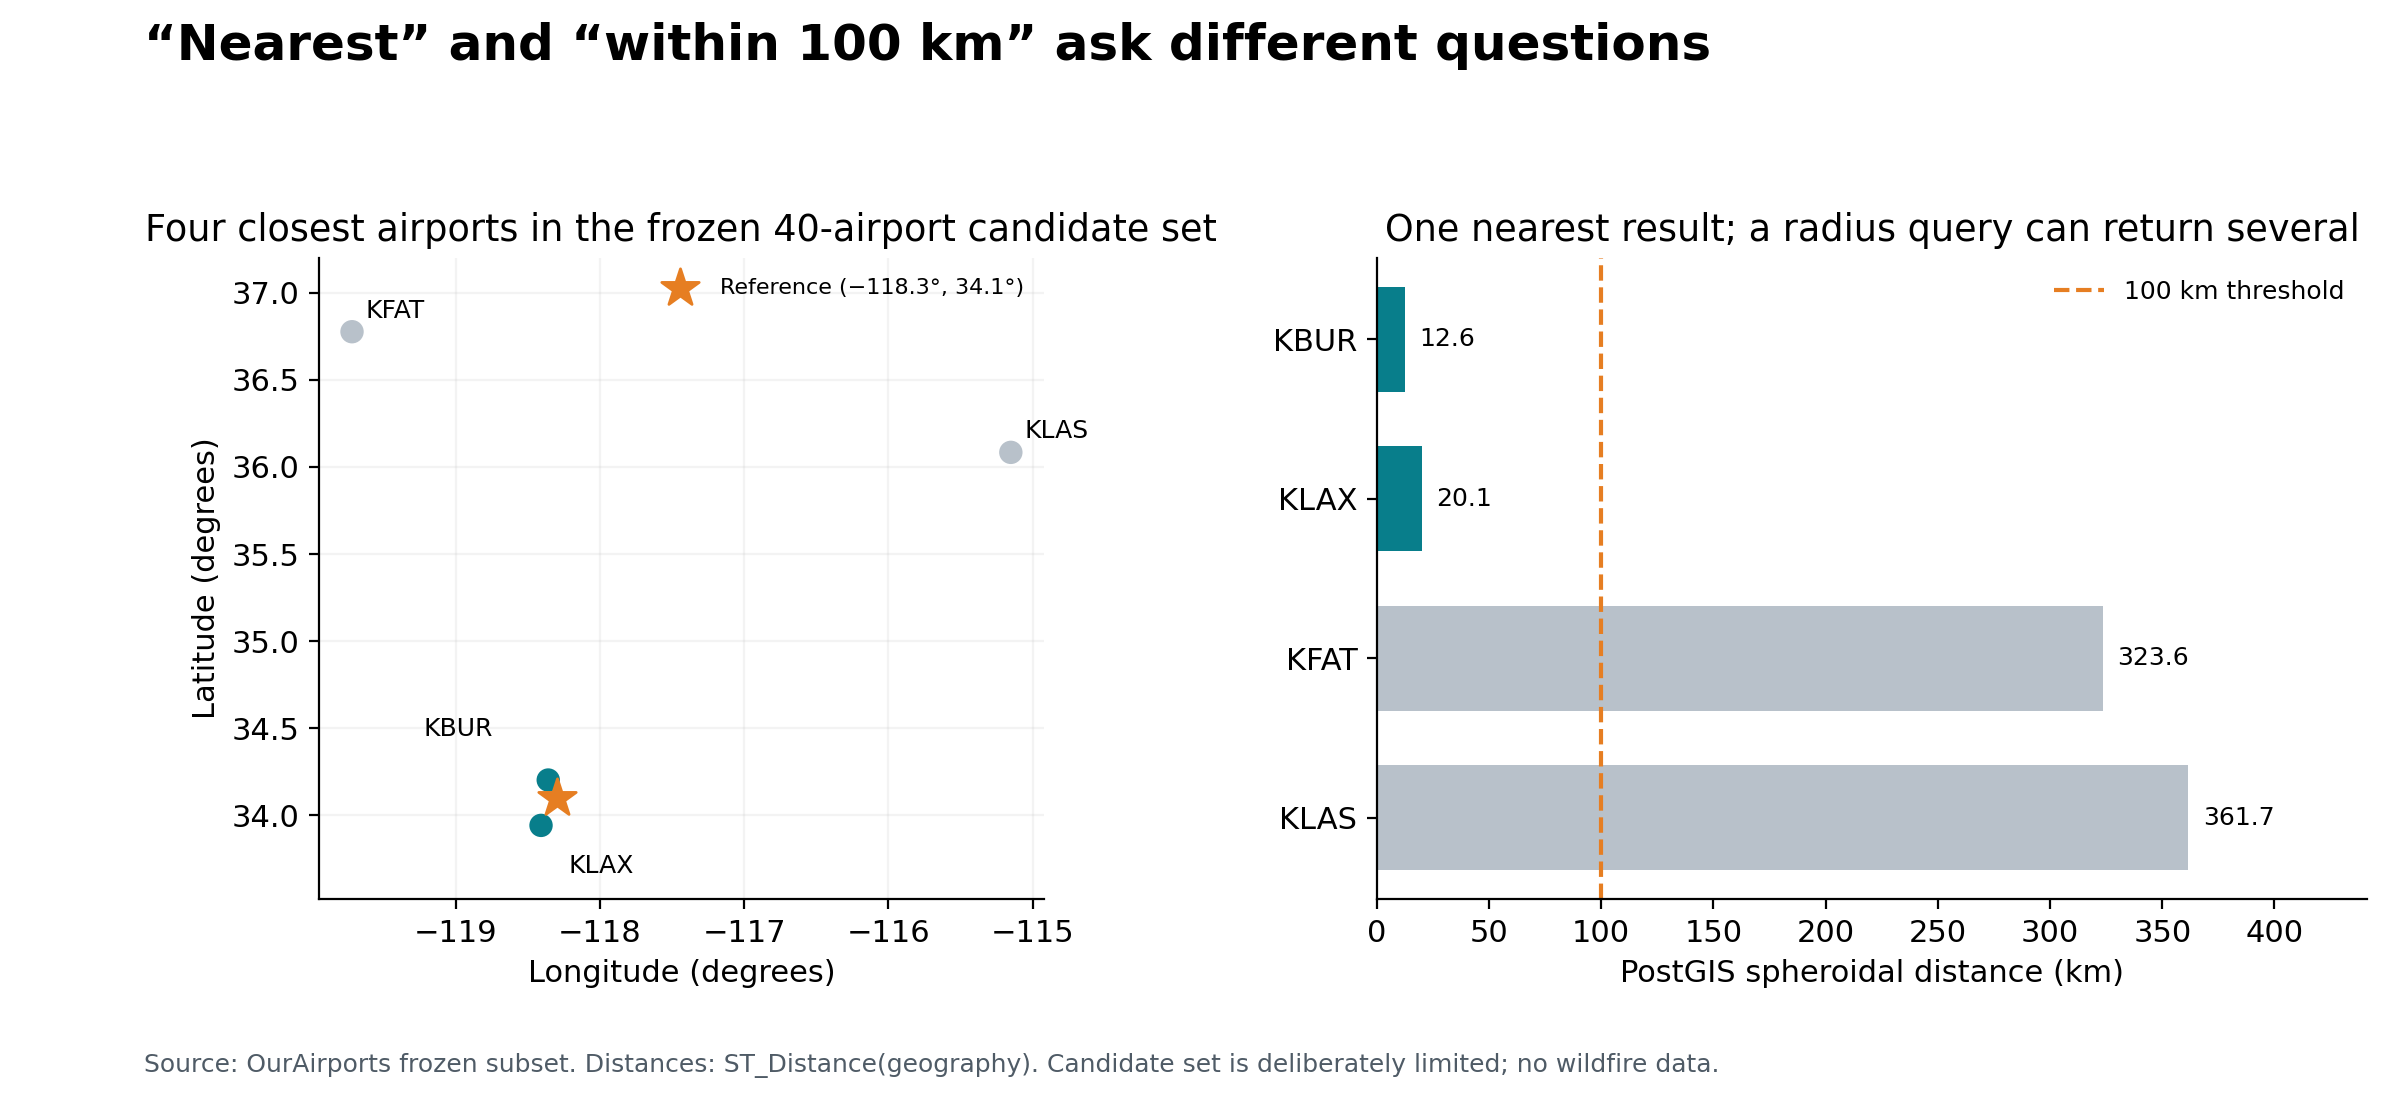

In [4]:
from IPython.display import Image, display
display(Image(filename="figure_1_airport_distances.png"))


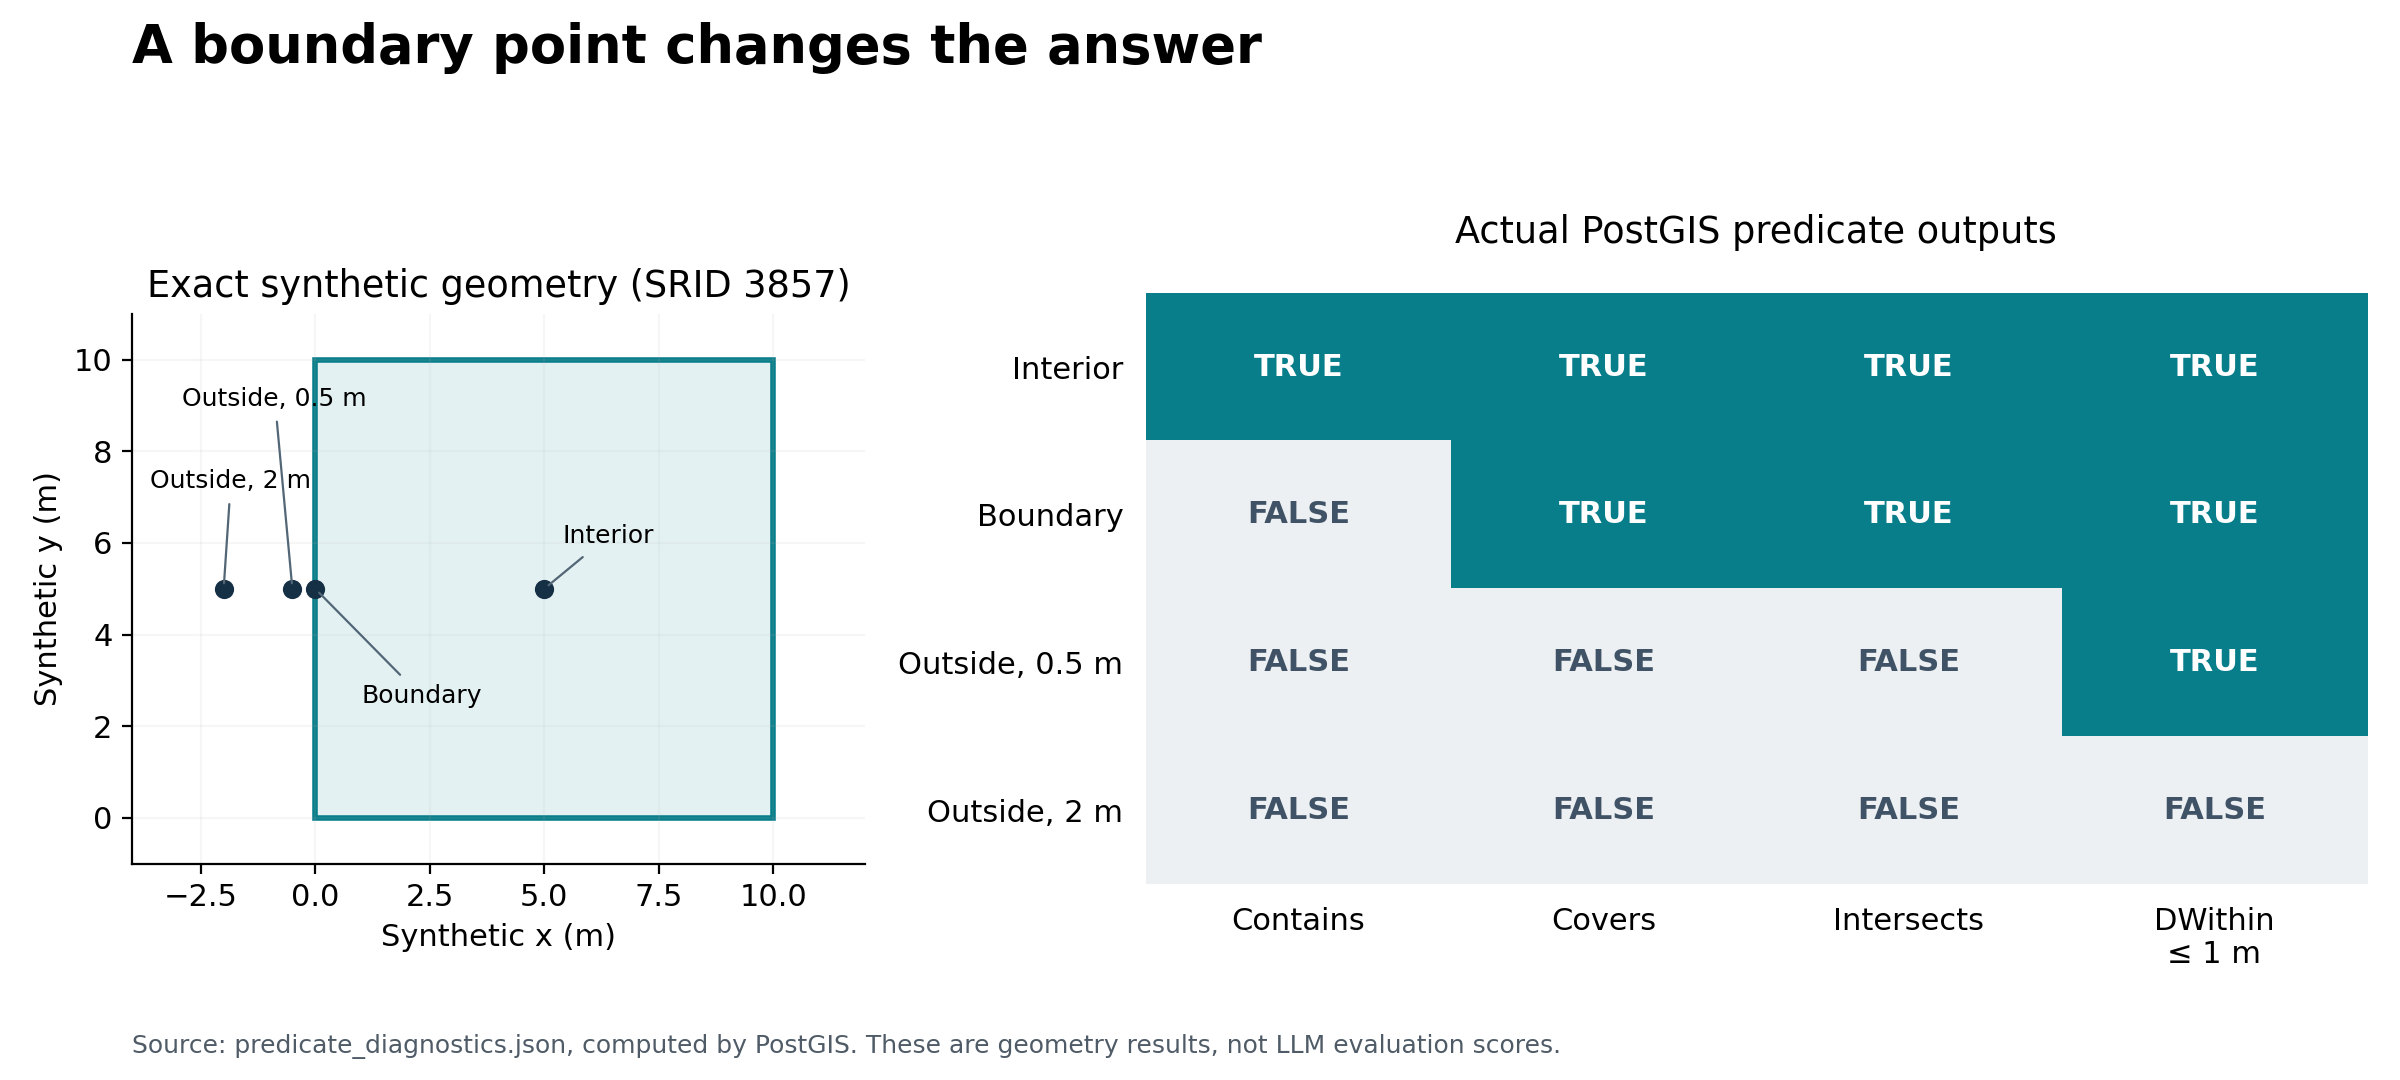

In [5]:
from IPython.display import Image, display
display(Image(filename="figure_2_boundary_predicates.png"))


## Interpretation and limits

The reference point near Los Angeles has one nearest eligible candidate (KBUR) and two eligible candidates within 100 km (KBUR and KLAX). The first figure shows the closest four of the frozen 40 candidates; it makes no claim about all airports or a real wildfire.

For a point on the exact polygon boundary, Contains is false while Covers and Intersects are true. A point 0.5 projected meters outside is within the 1 m threshold but does not intersect. Those values come directly from PostGIS.

The evaluation runner and strict scorer are in evaluate.py. Model integration is untested, scores are pending, and model_results.csv is deliberately header-only. Publish reviewed raw API responses and measured scores before making LLM performance claims.
